In [ ]:
print("Heart Disease Research")

Heart Disease Research


In [ ]:
!pip install -U ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# Load the UCI Heart Disease dataset
heart_disease = fetch_ucirepo(id=45)

# Separate input features and target
X = heart_disease.data.features
y = heart_disease.data.targets

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Features shape: (303, 13)
Target shape: (303, 1)


In [ ]:
# Display the first 5 rows
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [ ]:
# Check data types and missing values
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


In [ ]:
# Check the target values and their counts
print(y.value_counts())

num
0      164
1       55
2       36
3       35
4       13
Name: count, dtype: int64


In [ ]:
# Convert the target into a binary classification problem
y_binary = (y["num"] > 0).astype(int)

# Check the new target
print(y_binary.value_counts())

num
0    164
1    139
Name: count, dtype: int64


In [ ]:
# Count missing values in each feature
missing_values = X.isnull().sum()

print(missing_values)

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64


In [ ]:
# Show rows where ca or thal is missing
X[X["ca"].isnull() | X["thal"].isnull()][["ca", "thal"]]

,ca,thal
87,0.0,NaN
166,NaN,3.0
192,NaN,7.0
266,0.0,NaN
287,NaN,7.0
302,NaN,3.0


In [ ]:
# Summary statistics for all features
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [ ]:
# splittin the data for 80% training and 20% testing
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (242, 13)
Testing data: (61, 13)


In [ ]:
# Training our first model: Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Create a preprocessing + model pipeline
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Making predictions and calculating the baseline results
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Make predictions on the test data
y_pred = logistic_model.predict(X_test)

# Get probability of heart disease
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression - Baseline Results")
print("--------------------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression - Baseline Results
--------------------------------------
Accuracy  : 0.8689
Precision : 0.8125
Recall    : 0.9286
F1 Score  : 0.8667
ROC-AUC   : 0.9524

Confusion Matrix:
[[27  6]
 [ 2 26]]


In [ ]:
# Baseline KNN model
from sklearn.neighbors import KNeighborsClassifier

# Create KNN pipeline
knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

# Calculate metrics
print("KNN - Baseline Results")
print("----------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_knn):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_knn):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_knn):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_knn):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN - Baseline Results
----------------------
Accuracy  : 0.7049
Precision : 0.7273
Recall    : 0.5714
F1 Score  : 0.6400
ROC-AUC   : 0.7819

Confusion Matrix:
[[27  6]
 [12 16]]


In [ ]:
# KNN with standardization
from sklearn.preprocessing import StandardScaler

# KNN with standardization
knn_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# Train
knn_scaled.fit(X_train, y_train)

# Predictions
y_pred_knn_scaled = knn_scaled.predict(X_test)
y_prob_knn_scaled = knn_scaled.predict_proba(X_test)[:, 1]

# Results
print("KNN + StandardScaler Results")
print("----------------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_knn_scaled):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_knn_scaled):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_knn_scaled):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_knn_scaled):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_knn_scaled):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn_scaled))

KNN + StandardScaler Results
----------------------------
Accuracy  : 0.8852
Precision : 0.8000
Recall    : 1.0000
F1 Score  : 0.8889
ROC-AUC   : 0.9232

Confusion Matrix:
[[26  7]
 [ 0 28]]


In [ ]:
# KNN Min-Max Scaling
from sklearn.preprocessing import MinMaxScaler

# KNN with Min-Max scaling
knn_minmax = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# Train
knn_minmax.fit(X_train, y_train)

# Predictions
y_pred_knn_minmax = knn_minmax.predict(X_test)
y_prob_knn_minmax = knn_minmax.predict_proba(X_test)[:, 1]

# Results
print("KNN + MinMaxScaler Results")
print("--------------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_knn_minmax):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_knn_minmax):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_knn_minmax):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_knn_minmax):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_knn_minmax):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn_minmax))

KNN + MinMaxScaler Results
--------------------------
Accuracy  : 0.8033
Precision : 0.7500
Recall    : 0.8571
F1 Score  : 0.8000
ROC-AUC   : 0.8701

Confusion Matrix:
[[25  8]
 [ 4 24]]


In [ ]:
# Logistic Regression with StandardScaler

logistic_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Train
logistic_scaled.fit(X_train, y_train)

# Predictions
y_pred_lr_scaled = logistic_scaled.predict(X_test)
y_prob_lr_scaled = logistic_scaled.predict_proba(X_test)[:, 1]

# Results
print("Logistic Regression + StandardScaler Results")
print("---------------------------------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_lr_scaled):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_lr_scaled):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_lr_scaled):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_lr_scaled):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_lr_scaled):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_scaled))

Logistic Regression + StandardScaler Results
---------------------------------------------
Accuracy  : 0.8689
Precision : 0.8125
Recall    : 0.9286
F1 Score  : 0.8667
ROC-AUC   : 0.9513

Confusion Matrix:
[[27  6]
 [ 2 26]]


In [ ]:
# SVM Baseline

from sklearn.svm import SVC

# SVM without scaling
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", SVC(probability=True, random_state=42))
])

# Train
svm_model.fit(X_train, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

# Results
print("SVM - Baseline Results")
print("----------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_svm):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_svm):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_svm):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_svm):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM - Baseline Results
----------------------
Accuracy  : 0.6885
Precision : 0.7143
Recall    : 0.5357
F1 Score  : 0.6122
ROC-AUC   : 0.7944

Confusion Matrix:
[[27  6]
 [13 15]]


In [ ]:
# SVM with StandardScaler

svm_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True, random_state=42))
])

# Train
svm_scaled.fit(X_train, y_train)

# Predictions
y_pred_svm_scaled = svm_scaled.predict(X_test)
y_prob_svm_scaled = svm_scaled.predict_proba(X_test)[:, 1]

# Results
print("SVM + StandardScaler Results")
print("----------------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_svm_scaled):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_svm_scaled):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_svm_scaled):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_svm_scaled):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_svm_scaled):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm_scaled))

SVM + StandardScaler Results
----------------------------
Accuracy  : 0.8525
Precision : 0.8065
Recall    : 0.8929
F1 Score  : 0.8475
ROC-AUC   : 0.9437

Confusion Matrix:
[[27  6]
 [ 3 25]]


In [ ]:
# Decision Tree Baseline
from sklearn.tree import DecisionTreeClassifier

# Decision Tree without scaling
dt_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Train
dt_model.fit(X_train, y_train)

# Predictions
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Results
print("Decision Tree - Baseline Results")
print("--------------------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_dt):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_dt):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree - Baseline Results
--------------------------------
Accuracy  : 0.7377
Precision : 0.6765
Recall    : 0.8214
F1 Score  : 0.7419
ROC-AUC   : 0.7440

Confusion Matrix:
[[22 11]
 [ 5 23]]


In [ ]:
# Random Forest Baseline
from sklearn.ensemble import RandomForestClassifier

# Random Forest baseline
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Train
rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Results
print("Random Forest - Baseline Results")
print("---------------------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest - Baseline Results
---------------------------------
Accuracy  : 0.8852
Precision : 0.8387
Recall    : 0.9286
F1 Score  : 0.8814
ROC-AUC   : 0.9518

Confusion Matrix:
[[28  5]
 [ 2 26]]


In [ ]:
# Naive Bayes Baseline
from sklearn.naive_bayes import GaussianNB

# Naive Bayes baseline
nb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GaussianNB())
])

# Train
nb_model.fit(X_train, y_train)

# Predictions
y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

# Results
print("Naive Bayes - Baseline Results")
print("------------------------------")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_nb):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_nb):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_nb):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_nb):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes - Baseline Results
------------------------------
Accuracy  : 0.8689
Precision : 0.7941
Recall    : 0.9643
F1 Score  : 0.8710
ROC-AUC   : 0.9524

Confusion Matrix:
[[26  7]
 [ 1 27]]


In [ ]:
import pandas as pd

# Baseline results summary

results = {
    "Logistic Regression": [0.8689, 0.8125, 0.9286, 0.8667, 0.9524],
    "KNN": [0.7049, 0.7273, 0.5714, 0.6400, 0.7819],
    "SVM": [0.6885, 0.7143, 0.5357, 0.6122, 0.7944],
    "Decision Tree": [0.7377, 0.6765, 0.8214, 0.7419, 0.7440],
    "Random Forest": [0.8852, 0.8387, 0.9286, 0.8814, 0.9518],
    "Naive Bayes": [0.8689, 0.7941, 0.9643, 0.8710, 0.9524]
}

results_df = pd.DataFrame(
    results,
    index=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
).T

results_df

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.8689,0.8125,0.9286,0.8667,0.9524
KNN,0.7049,0.7273,0.5714,0.6400,0.7819
SVM,0.6885,0.7143,0.5357,0.6122,0.7944
Decision Tree,0.7377,0.6765,0.8214,0.7419,0.7440
Random Forest,0.8852,0.8387,0.9286,0.8814,0.9518
Naive Bayes,0.8689,0.7941,0.9643,0.8710,0.9524


In [ ]:
# 5-Fold Cross Validation
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create 5 folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Models we already created
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "SVM": svm_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Naive Bayes": nb_model
}

# Metrics to evaluate
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Run cross-validation
cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y_binary,
        cv=cv,
        scoring=scoring
    )

    cv_results[name] = {
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    }

cv_df = pd.DataFrame(cv_results).T

cv_df

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.834863,0.841458,0.791270,0.813935,0.908982
KNN,0.630437,0.606965,0.561640,0.579395,0.691758
SVM,0.647158,0.693871,0.425926,0.519331,0.749810
Decision Tree,0.765464,0.744874,0.762698,0.750771,0.765535
Random Forest,0.838142,0.854709,0.783862,0.816568,0.908259
Naive Bayes,0.854645,0.863163,0.820106,0.838457,0.902211


In [ ]:
# 5-fold cross-validation for KNN + StandardScaler

knn_scaled_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_scaled_scores = cross_validate(
    knn_scaled_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("KNN + StandardScaler - 5 Fold CV")
print("--------------------------------")
print(f"Accuracy  : {knn_scaled_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {knn_scaled_scores['test_precision'].mean():.4f}")
print(f"Recall    : {knn_scaled_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {knn_scaled_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {knn_scaled_scores['test_roc_auc'].mean():.4f}")

KNN + StandardScaler - 5 Fold CV
--------------------------------
Accuracy  : 0.8218
Precision : 0.8249
Recall    : 0.7772
F1 Score  : 0.7995
ROC-AUC   : 0.8820


In [ ]:
# 5-fold cross-validation for SVM + StandardScaler

svm_scaled_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True, random_state=42))
])

svm_scaled_scores = cross_validate(
    svm_scaled_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("SVM + StandardScaler - 5 Fold CV")
print("--------------------------------")
print(f"Accuracy  : {svm_scaled_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {svm_scaled_scores['test_precision'].mean():.4f}")
print(f"Recall    : {svm_scaled_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {svm_scaled_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {svm_scaled_scores['test_roc_auc'].mean():.4f}")

SVM + StandardScaler - 5 Fold CV
--------------------------------
Accuracy  : 0.8381
Precision : 0.8526
Recall    : 0.7839
F1 Score  : 0.8153
ROC-AUC   : 0.8975


In [ ]:
# 5-fold cross-validation for SVM without scaling

svm_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", SVC(probability=True, random_state=42))
])

svm_scores = cross_validate(
    svm_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("SVM without Scaling - 5 Fold CV")
print("--------------------------------")
print(f"Accuracy  : {svm_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {svm_scores['test_precision'].mean():.4f}")
print(f"Recall    : {svm_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {svm_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {svm_scores['test_roc_auc'].mean():.4f}")

SVM without Scaling - 5 Fold CV
--------------------------------
Accuracy  : 0.6472
Precision : 0.6939
Recall    : 0.4259
F1 Score  : 0.5193
ROC-AUC   : 0.7498


In [ ]:
# 5-fold cross-validation for KNN + MinMaxScaler

knn_minmax_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("model", KNeighborsClassifier())
])

knn_minmax_scores = cross_validate(
    knn_minmax_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("KNN + MinMaxScaler - 5 Fold CV")
print("--------------------------------")
print(f"Accuracy  : {knn_minmax_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {knn_minmax_scores['test_precision'].mean():.4f}")
print(f"Recall    : {knn_minmax_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {knn_minmax_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {knn_minmax_scores['test_roc_auc'].mean():.4f}")

KNN + MinMaxScaler - 5 Fold CV
--------------------------------
Accuracy  : 0.8019
Precision : 0.7958
Recall    : 0.7698
F1 Score  : 0.7795
ROC-AUC   : 0.8543


In [ ]:
# 5-fold cross-validation for SVM + MinMaxScaler

svm_minmax_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("model", SVC(probability=True, random_state=42))
])

svm_minmax_scores = cross_validate(
    svm_minmax_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("SVM + MinMaxScaler - 5 Fold CV")
print("--------------------------------")
print(f"Accuracy  : {svm_minmax_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {svm_minmax_scores['test_precision'].mean():.4f}")
print(f"Recall    : {svm_minmax_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {svm_minmax_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {svm_minmax_scores['test_roc_auc'].mean():.4f}")

SVM + MinMaxScaler - 5 Fold CV
--------------------------------
Accuracy  : 0.8250
Precision : 0.8434
Recall    : 0.7624
F1 Score  : 0.8002
ROC-AUC   : 0.9003


In [ ]:
# 5-fold cross-validation for Logistic Regression + StandardScaler

lr_scaled_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_scaled_scores = cross_validate(
    lr_scaled_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Logistic Regression + StandardScaler - 5 Fold CV")
print("------------------------------------------------")
print(f"Accuracy  : {lr_scaled_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {lr_scaled_scores['test_precision'].mean():.4f}")
print(f"Recall    : {lr_scaled_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {lr_scaled_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {lr_scaled_scores['test_roc_auc'].mean():.4f}")

Logistic Regression + StandardScaler - 5 Fold CV
------------------------------------------------
Accuracy  : 0.8316
Precision : 0.8304
Recall    : 0.7984
F1 Score  : 0.8126
ROC-AUC   : 0.9116


In [ ]:
# 5-fold cross-validation for Logistic Regression + MinMaxScaler

lr_minmax_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_minmax_scores = cross_validate(
    lr_minmax_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Logistic Regression + MinMaxScaler - 5 Fold CV")
print("------------------------------------------------")
print(f"Accuracy  : {lr_minmax_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {lr_minmax_scores['test_precision'].mean():.4f}")
print(f"Recall    : {lr_minmax_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {lr_minmax_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {lr_minmax_scores['test_roc_auc'].mean():.4f}")

Logistic Regression + MinMaxScaler - 5 Fold CV
------------------------------------------------
Accuracy  : 0.8283
Precision : 0.8346
Recall    : 0.7841
F1 Score  : 0.8069
ROC-AUC   : 0.9097


In [ ]:
# 5-fold cross-validation for Decision Tree + StandardScaler

dt_scaled_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_scaled_scores = cross_validate(
    dt_scaled_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Decision Tree + StandardScaler - 5 Fold CV")
print("-------------------------------------------")
print(f"Accuracy  : {dt_scaled_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {dt_scaled_scores['test_precision'].mean():.4f}")
print(f"Recall    : {dt_scaled_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {dt_scaled_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {dt_scaled_scores['test_roc_auc'].mean():.4f}")

Decision Tree + StandardScaler - 5 Fold CV
-------------------------------------------
Accuracy  : 0.7655
Precision : 0.7449
Recall    : 0.7627
F1 Score  : 0.7508
ROC-AUC   : 0.7655


In [ ]:
# 5-fold cross-validation for Random Forest + StandardScaler

rf_scaled_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_scaled_scores = cross_validate(
    rf_scaled_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Random Forest + StandardScaler - 5 Fold CV")
print("-------------------------------------------")
print(f"Accuracy  : {rf_scaled_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {rf_scaled_scores['test_precision'].mean():.4f}")
print(f"Recall    : {rf_scaled_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {rf_scaled_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {rf_scaled_scores['test_roc_auc'].mean():.4f}")

Random Forest + StandardScaler - 5 Fold CV
-------------------------------------------
Accuracy  : 0.8447
Precision : 0.8622
Recall    : 0.7910
F1 Score  : 0.8242
ROC-AUC   : 0.9099


In [ ]:
# Logistic Regression + Feature Selection
from sklearn.feature_selection import SelectKBest, f_classif

lr_fs_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", SelectKBest(score_func=f_classif, k=6)),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_fs_scores = cross_validate(
    lr_fs_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Logistic Regression + SelectKBest (6 Features) - 5 Fold CV")
print("-----------------------------------------------------------")
print(f"Accuracy  : {lr_fs_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {lr_fs_scores['test_precision'].mean():.4f}")
print(f"Recall    : {lr_fs_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {lr_fs_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {lr_fs_scores['test_roc_auc'].mean():.4f}")

Logistic Regression + SelectKBest (6 Features) - 5 Fold CV
-----------------------------------------------------------
Accuracy  : 0.8316
Precision : 0.8454
Recall    : 0.7767
F1 Score  : 0.8078
ROC-AUC   : 0.9042


In [ ]:
# Find the 6 features selected by SelectKBest

selector = SelectKBest(score_func=f_classif, k=6)

X_imputed = SimpleImputer(strategy="median").fit_transform(X)

X_selected = selector.fit_transform(
    StandardScaler().fit_transform(X_imputed),
    y_binary
)

selected_features = X.columns[selector.get_support()]

print("Selected 6 Features:")
print("--------------------")

for feature in selected_features:
    print(feature)

Selected 6 Features:
--------------------
cp
thalach
exang
oldpeak
ca
thal


In [ ]:
# KNN + SelectKBest (6 features) + StandardScaler

knn_fs_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", SelectKBest(score_func=f_classif, k=6)),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_fs_scores = cross_validate(
    knn_fs_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("KNN + SelectKBest (6 Features) - 5 Fold CV")
print("--------------------------------------------")
print(f"Accuracy  : {knn_fs_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {knn_fs_scores['test_precision'].mean():.4f}")
print(f"Recall    : {knn_fs_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {knn_fs_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {knn_fs_scores['test_roc_auc'].mean():.4f}")

KNN + SelectKBest (6 Features) - 5 Fold CV
--------------------------------------------
Accuracy  : 0.8316
Precision : 0.8516
Recall    : 0.7696
F1 Score  : 0.8068
ROC-AUC   : 0.8772


In [ ]:
# SVM + SelectKBest (6 features) + StandardScaler

svm_fs_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", SelectKBest(score_func=f_classif, k=6)),
    ("model", SVC(probability=True, random_state=42))
])

svm_fs_scores = cross_validate(
    svm_fs_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("SVM + SelectKBest (6 Features) - 5 Fold CV")
print("--------------------------------------------")
print(f"Accuracy  : {svm_fs_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {svm_fs_scores['test_precision'].mean():.4f}")
print(f"Recall    : {svm_fs_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {svm_fs_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {svm_fs_scores['test_roc_auc'].mean():.4f}")

SVM + SelectKBest (6 Features) - 5 Fold CV
--------------------------------------------
Accuracy  : 0.8283
Precision : 0.8490
Recall    : 0.7624
F1 Score  : 0.8022
ROC-AUC   : 0.8986


In [ ]:
# Master Results Table - 5 Fold Cross Validation

master_results = pd.DataFrame([
    # Logistic Regression
    ["Logistic Regression", "None", 0.8349, 0.8415, 0.7913, 0.8139, 0.9090],
    ["Logistic Regression", "StandardScaler", 0.8316, 0.8304, 0.7984, 0.8126, 0.9116],
    ["Logistic Regression", "MinMaxScaler", 0.8283, 0.8346, 0.7841, 0.8069, 0.9097],
    ["Logistic Regression", "SelectKBest (6) + StandardScaler", 0.8316, 0.8454, 0.7767, 0.8078, 0.9042],

    # KNN
    ["KNN", "None", 0.6304, 0.6070, 0.5616, 0.5794, 0.6918],
    ["KNN", "StandardScaler", 0.8218, 0.8249, 0.7772, 0.7995, 0.8820],
    ["KNN", "MinMaxScaler", 0.8010, 0.7958, 0.7698, 0.7795, 0.8543],
    ["KNN", "SelectKBest (6) + StandardScaler", 0.8316, 0.8516, 0.7696, 0.8068, 0.8772],

    # SVM
    ["SVM", "None", 0.6472, 0.6939, 0.4259, 0.5193, 0.7498],
    ["SVM", "StandardScaler", 0.8381, 0.8526, 0.7839, 0.8153, 0.8975],
    ["SVM", "MinMaxScaler", 0.8250, 0.8434, 0.7624, 0.8002, 0.9003],
    ["SVM", "SelectKBest (6) + StandardScaler", 0.8283, 0.8490, 0.7624, 0.8022, 0.8986],

    # Decision Tree
    ["Decision Tree", "None", 0.7655, 0.7449, 0.7627, 0.7508, 0.7655],
    ["Decision Tree", "StandardScaler", 0.7655, 0.7449, 0.7627, 0.7508, 0.7655],

    # Random Forest
    ["Random Forest", "None", 0.8381, 0.8547, 0.7839, 0.8166, 0.9083],
    ["Random Forest", "StandardScaler", 0.8447, 0.8622, 0.7910, 0.8242, 0.9099],

], columns=[
    "Algorithm",
    "Preprocessing",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
])

# Display percentages
master_results_display = master_results.copy()

for column in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    master_results_display[column] = (
        master_results_display[column] * 100
    ).round(2)

master_results_display

,Algorithm,Preprocessing,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,None,83.49,84.15,79.13,81.39,90.90
1,Logistic Regression,StandardScaler,83.16,83.04,79.84,81.26,91.16
2,Logistic Regression,MinMaxScaler,82.83,83.46,78.41,80.69,90.97
3,Logistic Regression,SelectKBest (6) + StandardScaler,83.16,84.54,77.67,80.78,90.42
4,KNN,None,63.04,60.70,56.16,57.94,69.18
5,KNN,StandardScaler,82.18,82.49,77.72,79.95,88.20
6,KNN,MinMaxScaler,80.10,79.58,76.98,77.95,85.43
7,KNN,SelectKBest (6) + StandardScaler,83.16,85.16,76.96,80.68,87.72
8,SVM,None,64.72,69.39,42.59,51.93,74.98
9,SVM,StandardScaler,83.81,85.26,78.39,81.53,89.75


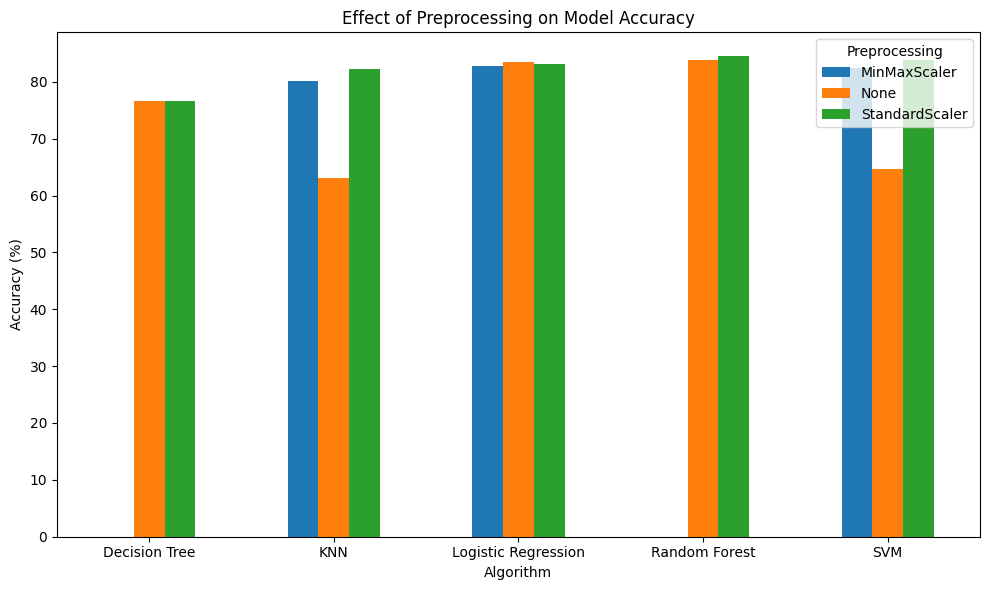

In [ ]:
# visualize the scaling effect
import matplotlib.pyplot as plt

# Select only the experiments without feature selection
scaling_results = master_results[
    ~master_results["Preprocessing"].str.contains("SelectKBest")
].copy()

# Convert accuracy to percentage
scaling_results["Accuracy (%)"] = scaling_results["Accuracy"] * 100

# Create pivot table
accuracy_pivot = scaling_results.pivot(
    index="Algorithm",
    columns="Preprocessing",
    values="Accuracy (%)"
)

# Plot
accuracy_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Effect of Preprocessing on Model Accuracy")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.legend(title="Preprocessing")
plt.tight_layout()
plt.show()

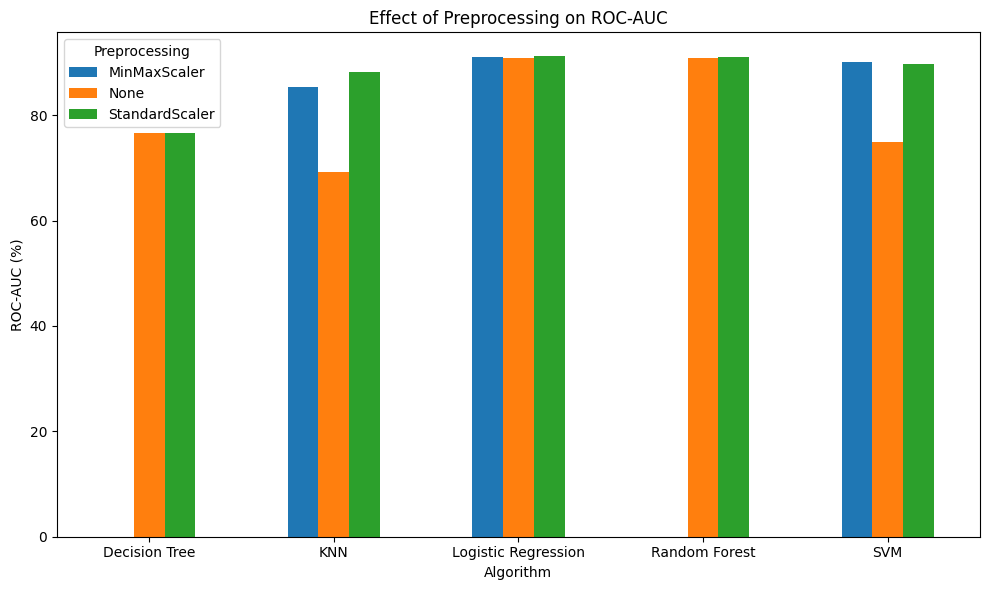

In [ ]:
# ROC-AUC comparison for different preprocessing methods

roc_results = master_results[
    ~master_results["Preprocessing"].str.contains("SelectKBest")
].copy()

# Convert ROC-AUC to percentage
roc_results["ROC-AUC (%)"] = roc_results["ROC-AUC"] * 100

# Create pivot table
roc_pivot = roc_results.pivot(
    index="Algorithm",
    columns="Preprocessing",
    values="ROC-AUC (%)"
)

# Plot
roc_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Effect of Preprocessing on ROC-AUC")
plt.xlabel("Algorithm")
plt.ylabel("ROC-AUC (%)")
plt.xticks(rotation=0)
plt.legend(title="Preprocessing")
plt.tight_layout()
plt.show()

In [ ]:
# Calculate the effect of scaling

baseline = master_results[
    master_results["Preprocessing"] == "None"
].set_index("Algorithm")

standard = master_results[
    master_results["Preprocessing"] == "StandardScaler"
].set_index("Algorithm")

comparison = pd.DataFrame(index=baseline.index)

comparison["Accuracy - None (%)"] = baseline["Accuracy"] * 100
comparison["Accuracy - StandardScaler (%)"] = standard["Accuracy"] * 100

comparison["Accuracy Change (pp)"] = (
    comparison["Accuracy - StandardScaler (%)"]
    - comparison["Accuracy - None (%)"]
)

comparison["ROC-AUC - None (%)"] = baseline["ROC-AUC"] * 100
comparison["ROC-AUC - StandardScaler (%)"] = standard["ROC-AUC"] * 100

comparison["ROC-AUC Change (pp)"] = (
    comparison["ROC-AUC - StandardScaler (%)"]
    - comparison["ROC-AUC - None (%)"]
)

comparison.round(2)

,Accuracy - None (%),Accuracy - StandardScaler (%),Accuracy Change (pp),ROC-AUC - None (%),ROC-AUC - StandardScaler (%),ROC-AUC Change (pp)
Algorithm,,,,,,
Logistic Regression,83.49,83.16,-0.33,90.90,91.16,0.26
KNN,63.04,82.18,19.14,69.18,88.20,19.02
SVM,64.72,83.81,19.09,74.98,89.75,14.77
Decision Tree,76.55,76.55,0.00,76.55,76.55,0.00
Random Forest,83.81,84.47,0.66,90.83,90.99,0.16


In [ ]:
# Calculate the effect of feature selection

all_features = master_results[
    master_results["Preprocessing"].isin([
        "StandardScaler"
    ])
].set_index("Algorithm")

selected_features = master_results[
    master_results["Preprocessing"].str.contains("SelectKBest")
].set_index("Algorithm")

feature_comparison = pd.DataFrame(index=all_features.index)

feature_comparison["Accuracy - 13 Features (%)"] = (
    all_features["Accuracy"] * 100
)

feature_comparison["Accuracy - 6 Features (%)"] = (
    selected_features["Accuracy"] * 100
)

feature_comparison["Accuracy Change (pp)"] = (
    feature_comparison["Accuracy - 6 Features (%)"]
    - feature_comparison["Accuracy - 13 Features (%)"]
)

feature_comparison["ROC-AUC - 13 Features (%)"] = (
    all_features["ROC-AUC"] * 100
)

feature_comparison["ROC-AUC - 6 Features (%)"] = (
    selected_features["ROC-AUC"] * 100
)

feature_comparison["ROC-AUC Change (pp)"] = (
    feature_comparison["ROC-AUC - 6 Features (%)"]
    - feature_comparison["ROC-AUC - 13 Features (%)"]
)

feature_comparison.round(2)

,Accuracy - 13 Features (%),Accuracy - 6 Features (%),Accuracy Change (pp),ROC-AUC - 13 Features (%),ROC-AUC - 6 Features (%),ROC-AUC Change (pp)
Algorithm,,,,,,
Logistic Regression,83.16,83.16,0.00,91.16,90.42,-0.74
KNN,82.18,83.16,0.98,88.20,87.72,-0.48
SVM,83.81,82.83,-0.98,89.75,89.86,0.11
Decision Tree,76.55,NaN,NaN,76.55,NaN,NaN
Random Forest,84.47,NaN,NaN,90.99,NaN,NaN


In [ ]:
# Test different numbers of selected features

k_values = [3, 6, 9, 13]

feature_count_results = []

for k in k_values:

    lr_k_cv = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("feature_selection", SelectKBest(score_func=f_classif, k=k)),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ])

    scores = cross_validate(
        lr_k_cv,
        X,
        y_binary,
        cv=cv,
        scoring=scoring
    )

    feature_count_results.append([
        k,
        scores["test_accuracy"].mean(),
        scores["test_precision"].mean(),
        scores["test_recall"].mean(),
        scores["test_f1"].mean(),
        scores["test_roc_auc"].mean()
    ])

feature_count_results = pd.DataFrame(
    feature_count_results,
    columns=[
        "Number of Features",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
)

# Convert to percentage
feature_count_display = feature_count_results.copy()

for column in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    feature_count_display[column] = (
        feature_count_display[column] * 100
    ).round(2)

feature_count_display

,Number of Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,3,79.84,79.06,76.24,77.55,86.25
1,6,83.16,84.54,77.67,80.78,90.42
2,9,83.49,84.72,78.39,81.17,91.04
3,13,83.16,83.04,79.84,81.26,91.16


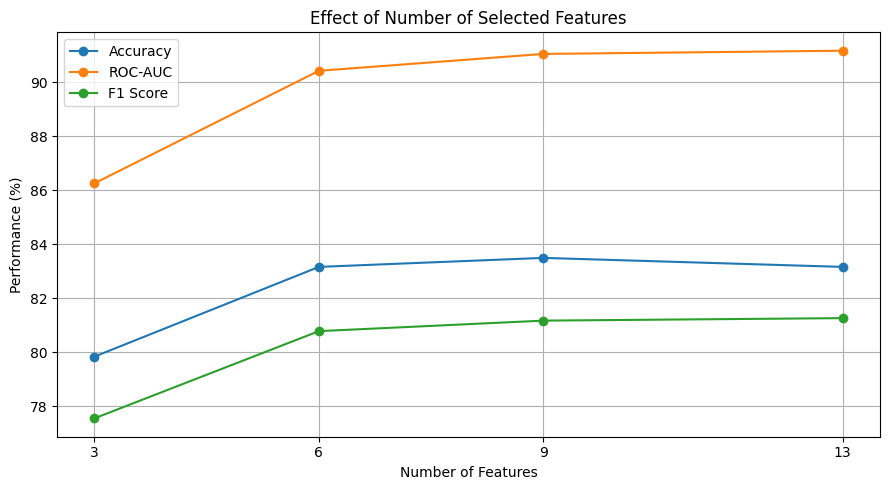

In [ ]:
# Visualize effect of number of selected features

plt.figure(figsize=(9, 5))

plt.plot(
    feature_count_results["Number of Features"],
    feature_count_results["Accuracy"] * 100,
    marker="o",
    label="Accuracy"
)

plt.plot(
    feature_count_results["Number of Features"],
    feature_count_results["ROC-AUC"] * 100,
    marker="o",
    label="ROC-AUC"
)

plt.plot(
    feature_count_results["Number of Features"],
    feature_count_results["F1"] * 100,
    marker="o",
    label="F1 Score"
)

plt.title("Effect of Number of Selected Features")
plt.xlabel("Number of Features")
plt.ylabel("Performance (%)")
plt.xticks([3, 6, 9, 13])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.feature_selection import RFE

# Logistic Regression + RFE (6 features) + StandardScaler

lr_rfe_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", RFE(
        estimator=LogisticRegression(max_iter=1000, random_state=42),
        n_features_to_select=6
    )),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_rfe_scores = cross_validate(
    lr_rfe_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Logistic Regression + RFE (6 Features) - 5 Fold CV")
print("--------------------------------------------------")
print(f"Accuracy  : {lr_rfe_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {lr_rfe_scores['test_precision'].mean():.4f}")
print(f"Recall    : {lr_rfe_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {lr_rfe_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {lr_rfe_scores['test_roc_auc'].mean():.4f}")

Logistic Regression + RFE (6 Features) - 5 Fold CV
--------------------------------------------------
Accuracy  : 0.8052
Precision : 0.8018
Recall    : 0.7696
F1 Score  : 0.7825
ROC-AUC   : 0.8867


In [ ]:
# Find the 6 features selected by RFE

X_imputed = SimpleImputer(strategy="median").fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

rfe_selector = RFE(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    n_features_to_select=6
)

rfe_selector.fit(X_scaled, y_binary)

rfe_features = X.columns[rfe_selector.support_]

print("RFE Selected 6 Features:")
print("------------------------")

for feature in rfe_features:
    print(feature)

RFE Selected 6 Features:
------------------------
sex
cp
exang
oldpeak
ca
thal


In [ ]:
# RFE with different number of features
rfe_feature_counts = [3, 6, 9, 13]

rfe_count_results = []

for n_features in rfe_feature_counts:

    rfe_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=LogisticRegression(max_iter=1000, random_state=42),
            n_features_to_select=n_features
        )),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ])

    scores = cross_validate(
        rfe_pipeline,
        X,
        y_binary,
        cv=cv,
        scoring=scoring
    )

    rfe_count_results.append({
        "Number of Features": n_features,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

rfe_count_results = pd.DataFrame(rfe_count_results)

rfe_count_display = rfe_count_results.copy()

for column in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    rfe_count_display[column] = (
        rfe_count_display[column] * 100
    ).round(2)

rfe_count_display

,Number of Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,3,80.52,82.22,74.10,77.69,86.57
1,6,80.52,80.18,76.96,78.25,88.67
2,9,82.17,81.95,79.13,80.21,90.69
3,13,83.16,83.04,79.84,81.26,91.16


In [ ]:
# Combinin our main results
feature_selection_summary = pd.DataFrame({
    "Method": [
        "All Features (13)",
        "SelectKBest (6)",
        "RFE (6)"
    ],
    "Accuracy": [
        83.16,
        83.16,
        80.52
    ],
    "Precision": [
        83.04,
        84.54,
        80.18
    ],
    "Recall": [
        79.84,
        77.67,
        76.96
    ],
    "F1": [
        81.26,
        80.78,
        78.25
    ],
    "ROC-AUC": [
        91.16,
        90.42,
        88.67
    ]
})

feature_selection_summary

,Method,Accuracy,Precision,Recall,F1,ROC-AUC
0,All Features (13),83.16,83.04,79.84,81.26,91.16
1,SelectKBest (6),83.16,84.54,77.67,80.78,90.42
2,RFE (6),80.52,80.18,76.96,78.25,88.67


In [ ]:
# LR + StandadScaler + 5-fold CV + 6 selection features
from sklearn.feature_selection import SelectKBest, mutual_info_classif

lr_mi_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", SelectKBest(
        score_func=mutual_info_classif,
        k=6
    )),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_mi_scores = cross_validate(
    lr_mi_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Logistic Regression + Mutual Information (6 Features) - 5 Fold CV")
print("---------------------------------------------------------------")
print(f"Accuracy  : {lr_mi_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {lr_mi_scores['test_precision'].mean():.4f}")
print(f"Recall    : {lr_mi_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {lr_mi_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {lr_mi_scores['test_roc_auc'].mean():.4f}")

Logistic Regression + Mutual Information (6 Features) - 5 Fold CV
---------------------------------------------------------------
Accuracy  : 0.8316
Precision : 0.8424
Recall    : 0.7841
F1 Score  : 0.8097
ROC-AUC   : 0.8990


In [ ]:
# Find the 6 features selected by Mutual Information

mi_selector = SelectKBest(
    score_func=mutual_info_classif,
    k=6
)

X_imputed = SimpleImputer(strategy="median").fit_transform(X)
X_scaled = StandardScaler().fit_transform(X_imputed)

mi_selector.fit(X_scaled, y_binary)

mi_features = X.columns[mi_selector.get_support()]

print("Mutual Information Selected 6 Features:")
print("----------------------------------------")

for feature in mi_features:
    print(feature)

Mutual Information Selected 6 Features:
----------------------------------------
cp
chol
thalach
oldpeak
ca
thal


In [ ]:
# KNN + Mutual Information (6 Features) + StandardScaler

knn_mi_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", SelectKBest(
        score_func=mutual_info_classif,
        k=6
    )),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_mi_scores = cross_validate(
    knn_mi_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("KNN + Mutual Information (6 Features) - 5 Fold CV")
print("--------------------------------------------------")
print(f"Accuracy  : {knn_mi_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {knn_mi_scores['test_precision'].mean():.4f}")
print(f"Recall    : {knn_mi_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {knn_mi_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {knn_mi_scores['test_roc_auc'].mean():.4f}")

KNN + Mutual Information (6 Features) - 5 Fold CV
--------------------------------------------------
Accuracy  : 0.8185
Precision : 0.8518
Recall    : 0.7339
F1 Score  : 0.7873
ROC-AUC   : 0.8687


In [ ]:
# SVM + Mutual Information (6 Features) + StandardScaler

svm_mi_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", SelectKBest(
        score_func=mutual_info_classif,
        k=6
    )),
    ("model", SVC(probability=True, random_state=42))
])

svm_mi_scores = cross_validate(
    svm_mi_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("SVM + Mutual Information (6 Features) - 5 Fold CV")
print("--------------------------------------------------")
print(f"Accuracy  : {svm_mi_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {svm_mi_scores['test_precision'].mean():.4f}")
print(f"Recall    : {svm_mi_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {svm_mi_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {svm_mi_scores['test_roc_auc'].mean():.4f}")

SVM + Mutual Information (6 Features) - 5 Fold CV
--------------------------------------------------
Accuracy  : 0.8150
Precision : 0.8197
Recall    : 0.7693
F1 Score  : 0.7920
ROC-AUC   : 0.8855


In [ ]:
# Random Forest + Mutual Information (6 Features) - 5 Fold CV

rf_mi_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", SelectKBest(
        score_func=mutual_info_classif,
        k=6
    )),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_mi_scores = cross_validate(
    rf_mi_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Random Forest + Mutual Information (6 Features) - 5 Fold CV")
print("-----------------------------------------------------------")
print(f"Accuracy  : {rf_mi_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {rf_mi_scores['test_precision'].mean():.4f}")
print(f"Recall    : {rf_mi_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {rf_mi_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {rf_mi_scores['test_roc_auc'].mean():.4f}")

Random Forest + Mutual Information (6 Features) - 5 Fold CV
-----------------------------------------------------------
Accuracy  : 0.7954
Precision : 0.8008
Recall    : 0.7476
F1 Score  : 0.7691
ROC-AUC   : 0.8811


In [ ]:
# Naive Bayes + Mutual Information (6 Features) - 5 Fold CV

nb_mi_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("feature_selection", SelectKBest(
        score_func=mutual_info_classif,
        k=6
    )),
    ("model", GaussianNB())
])

nb_mi_scores = cross_validate(
    nb_mi_cv,
    X,
    y_binary,
    cv=cv,
    scoring=scoring
)

print("Naive Bayes + Mutual Information (6 Features) - 5 Fold CV")
print("---------------------------------------------------------")
print(f"Accuracy  : {nb_mi_scores['test_accuracy'].mean():.4f}")
print(f"Precision : {nb_mi_scores['test_precision'].mean():.4f}")
print(f"Recall    : {nb_mi_scores['test_recall'].mean():.4f}")
print(f"F1 Score  : {nb_mi_scores['test_f1'].mean():.4f}")
print(f"ROC-AUC   : {nb_mi_scores['test_roc_auc'].mean():.4f}")

Naive Bayes + Mutual Information (6 Features) - 5 Fold CV
---------------------------------------------------------
Accuracy  : 0.8051
Precision : 0.7957
Recall    : 0.7841
F1 Score  : 0.7877
ROC-AUC   : 0.8695


In [ ]:
import zipfile

zip_path = "/content/heart+disease.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside the ZIP:")
    for file in z.namelist():
        print(file)

Files inside the ZIP:
Index
WARNING
ask-detrano
bak
cleve.mod
cleveland.data
costs/
costs/Index
costs/heart-disease.README
costs/heart-disease.cost
costs/heart-disease.delay
costs/heart-disease.expense
costs/heart-disease.group
heart-disease.names
hungarian.data
long-beach-va.data
new.data
processed.cleveland.data
processed.hungarian.data
processed.switzerland.data
processed.va.data
reprocessed.hungarian.data
switzerland.data


In [ ]:
import zipfile

zip_path = "/content/heart+disease.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extract("processed.hungarian.data", "/content/")

print("Hungarian dataset extracted successfully!")

Hungarian dataset extracted successfully!


In [ ]:
# Inspecting the new dataset
with open("/content/processed.hungarian.data", "r") as f:
    for i in range(5):
        print(f.readline())

28,1,2,130,132,0,2,185,0,0,?,?,?,0

29,1,2,120,243,0,0,160,0,0,?,?,?,0

29,1,2,140,?,0,0,170,0,0,?,?,?,0

30,0,1,170,237,0,1,170,0,0,?,?,6,0

31,0,2,100,219,0,1,150,0,0,?,?,?,0



In [ ]:
import pandas as pd

hungarian = pd.read_csv(
    "/content/processed.hungarian.data",
    header=None,
    na_values="?"
)

print("Shape:", hungarian.shape)
print("\nMissing values:")
print(hungarian.isnull().sum())

Shape: (294, 14)

Missing values:
0       0
1       0
2       0
3       1
4      23
5       8
6       1
7       1
8       1
9       0
10    190
11    291
12    266
13      0
dtype: int64


In [ ]:
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

hungarian.columns = columns

print(hungarian.head())

   age  sex  cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0   28    1   2     130.0  132.0  0.0      2.0    185.0    0.0      0.0   
1   29    1   2     120.0  243.0  0.0      0.0    160.0    0.0      0.0   
2   29    1   2     140.0    NaN  0.0      0.0    170.0    0.0      0.0   
3   30    0   1     170.0  237.0  0.0      1.0    170.0    0.0      0.0   
4   31    0   2     100.0  219.0  0.0      1.0    150.0    0.0      0.0   

   slope  ca  thal  num  
0    NaN NaN   NaN    0  
1    NaN NaN   NaN    0  
2    NaN NaN   NaN    0  
3    NaN NaN   6.0    0  
4    NaN NaN   NaN    0  


In [ ]:
print(hungarian["num"].value_counts(dropna=False))

num
0    188
1    106
Name: count, dtype: int64


In [ ]:
# Checking the percentage of missing values
missing_percent = (hungarian.isnull().sum() / len(hungarian) * 100)

print(missing_percent.sort_values(ascending=False))

ca          98.979592
thal        90.476190
slope       64.625850
chol         7.823129
fbs          2.721088
trestbps     0.340136
thalach      0.340136
exang        0.340136
restecg      0.340136
age          0.000000
cp           0.000000
sex          0.000000
oldpeak      0.000000
num          0.000000
dtype: float64


In [ ]:
print(hungarian[
    ["age", "sex", "cp", "trestbps", "chol",
     "fbs", "restecg", "thalach", "exang", "oldpeak"]
].dtypes)

age           int64
sex           int64
cp            int64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
dtype: object


In [ ]:
for col in ["sex", "cp", "fbs", "restecg", "exang"]:
    print(f"{col}: {sorted(hungarian[col].dropna().unique())}")

sex: [np.int64(0), np.int64(1)]
cp: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
fbs: [np.float64(0.0), np.float64(1.0)]
restecg: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
exang: [np.float64(0.0), np.float64(1.0)]


In [ ]:
numeric_cols = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

print(hungarian[numeric_cols].describe())

              age    trestbps        chol     thalach     oldpeak
count  294.000000  293.000000  271.000000  293.000000  294.000000
mean    47.826531  132.583618  250.848708  139.129693    0.586054
std      7.811812   17.626568   67.657711   23.589749    0.908648
min     28.000000   92.000000   85.000000   82.000000    0.000000
25%     42.000000  120.000000  209.000000  122.000000    0.000000
50%     49.000000  130.000000  243.000000  140.000000    0.000000
75%     54.000000  140.000000  282.500000  155.000000    1.000000
max     66.000000  200.000000  603.000000  190.000000    5.000000


In [ ]:
features_hungarian = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang", "oldpeak"
]

X_hungarian = hungarian[features_hungarian]
y_hungarian = hungarian["num"]

print("X shape:", X_hungarian.shape)
print("y shape:", y_hungarian.shape)
print("Target distribution:")
print(y_hungarian.value_counts())

X shape: (294, 10)
y shape: (294,)
Target distribution:
num
0    188
1    106
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_hungarian,
    y_hungarian,
    test_size=0.20,
    random_state=42,
    stratify=y_hungarian
)

print("Training set:", X_train_h.shape)
print("Test set:", X_test_h.shape)

print("\nTraining target:")
print(y_train_h.value_counts())

print("\nTest target:")
print(y_test_h.value_counts())

Training set: (235, 10)
Test set: (59, 10)

Training target:
num
0    150
1     85
Name: count, dtype: int64

Test target:
num
0    38
1    21
Name: count, dtype: int64


In [ ]:
# Pipeline handles the missing data values
# Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

lr_hungarian = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

lr_hungarian.fit(X_train_h, y_train_h)

y_pred_h = lr_hungarian.predict(X_test_h)
y_prob_h = lr_hungarian.predict_proba(X_test_h)[:, 1]

print("Logistic Regression - Hungarian")
print("Accuracy :", accuracy_score(y_test_h, y_pred_h))
print("Precision:", precision_score(y_test_h, y_pred_h))
print("Recall   :", recall_score(y_test_h, y_pred_h))
print("F1 Score :", f1_score(y_test_h, y_pred_h))
print("ROC-AUC  :", roc_auc_score(y_test_h, y_prob_h))

Logistic Regression - Hungarian
Accuracy : 0.847457627118644
Precision: 0.8
Recall   : 0.7619047619047619
F1 Score : 0.7804878048780488
ROC-AUC  : 0.882205513784461


In [ ]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn_hungarian = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_hungarian.fit(X_train_h, y_train_h)

y_pred_knn_h = knn_hungarian.predict(X_test_h)
y_prob_knn_h = knn_hungarian.predict_proba(X_test_h)[:, 1]

print("KNN - Hungarian")
print("Accuracy :", accuracy_score(y_test_h, y_pred_knn_h))
print("Precision:", precision_score(y_test_h, y_pred_knn_h))
print("Recall   :", recall_score(y_test_h, y_pred_knn_h))
print("F1 Score :", f1_score(y_test_h, y_pred_knn_h))
print("ROC-AUC  :", roc_auc_score(y_test_h, y_prob_knn_h))

KNN - Hungarian
Accuracy : 0.864406779661017
Precision: 0.8421052631578947
Recall   : 0.7619047619047619
F1 Score : 0.8
ROC-AUC  : 0.8928571428571428


In [ ]:
# SVM
from sklearn.svm import SVC

svm_hungarian = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True))
])

svm_hungarian.fit(X_train_h, y_train_h)

y_pred_svm_h = svm_hungarian.predict(X_test_h)
y_prob_svm_h = svm_hungarian.predict_proba(X_test_h)[:, 1]

print("SVM - Hungarian")
print("Accuracy :", accuracy_score(y_test_h, y_pred_svm_h))
print("Precision:", precision_score(y_test_h, y_pred_svm_h))
print("Recall   :", recall_score(y_test_h, y_pred_svm_h))
print("F1 Score :", f1_score(y_test_h, y_pred_svm_h))
print("ROC-AUC  :", roc_auc_score(y_test_h, y_prob_svm_h))

SVM - Hungarian
Accuracy : 0.864406779661017
Precision: 0.8823529411764706
Recall   : 0.7142857142857143
F1 Score : 0.7894736842105263
ROC-AUC  : 0.9197994987468672


In [ ]:
# Decision Tree
from sklearn.tree import DecisionTreeClassifier

dt_hungarian = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_hungarian.fit(X_train_h, y_train_h)

y_pred_dt_h = dt_hungarian.predict(X_test_h)
y_prob_dt_h = dt_hungarian.predict_proba(X_test_h)[:, 1]

print("Decision Tree - Hungarian")
print("Accuracy :", accuracy_score(y_test_h, y_pred_dt_h))
print("Precision:", precision_score(y_test_h, y_pred_dt_h))
print("Recall   :", recall_score(y_test_h, y_pred_dt_h))
print("F1 Score :", f1_score(y_test_h, y_pred_dt_h))
print("ROC-AUC  :", roc_auc_score(y_test_h, y_prob_dt_h))

Decision Tree - Hungarian
Accuracy : 0.7627118644067796
Precision: 0.6666666666666666
Recall   : 0.6666666666666666
F1 Score : 0.6666666666666666
ROC-AUC  : 0.7412280701754385


In [ ]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_hungarian = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_hungarian.fit(X_train_h, y_train_h)

y_pred_rf_h = rf_hungarian.predict(X_test_h)
y_prob_rf_h = rf_hungarian.predict_proba(X_test_h)[:, 1]

print("Random Forest - Hungarian")
print("Accuracy :", accuracy_score(y_test_h, y_pred_rf_h))
print("Precision:", precision_score(y_test_h, y_pred_rf_h))
print("Recall   :", recall_score(y_test_h, y_pred_rf_h))
print("F1 Score :", f1_score(y_test_h, y_pred_rf_h))
print("ROC-AUC  :", roc_auc_score(y_test_h, y_prob_rf_h))

Random Forest - Hungarian
Accuracy : 0.7796610169491526
Precision: 0.7222222222222222
Recall   : 0.6190476190476191
F1 Score : 0.6666666666666666
ROC-AUC  : 0.8947368421052632


In [ ]:
# Naive Bayes
from sklearn.naive_bayes import GaussianNB

nb_hungarian = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GaussianNB())
])

nb_hungarian.fit(X_train_h, y_train_h)

y_pred_nb_h = nb_hungarian.predict(X_test_h)
y_prob_nb_h = nb_hungarian.predict_proba(X_test_h)[:, 1]

print("Naive Bayes - Hungarian")
print("Accuracy :", accuracy_score(y_test_h, y_pred_nb_h))
print("Precision:", precision_score(y_test_h, y_pred_nb_h))
print("Recall   :", recall_score(y_test_h, y_pred_nb_h))
print("F1 Score :", f1_score(y_test_h, y_pred_nb_h))
print("ROC-AUC  :", roc_auc_score(y_test_h, y_prob_nb_h))

Naive Bayes - Hungarian
Accuracy : 0.8813559322033898
Precision: 0.8181818181818182
Recall   : 0.8571428571428571
F1 Score : 0.8372093023255814
ROC-AUC  : 0.8734335839598998


In [ ]:
# 5-Fold cross validation
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

cv_h = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_h = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GaussianNB())
    ])
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results_h = []

for name, model in models_h.items():

    scores = cross_validate(
        model,
        X_hungarian,
        y_hungarian,
        cv=cv_h,
        scoring=scoring
    )

    cv_results_h.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_h = pd.DataFrame(cv_results_h)

print(cv_results_h.round(4))

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.8335     0.8100  0.7074  0.7540   0.8806
1                  KNN    0.8300     0.7972  0.7156  0.7507   0.8682
2                  SVM    0.8266     0.8097  0.6792  0.7381   0.8767
3        Decision Tree    0.7314     0.6340  0.6139  0.6213   0.7061
4        Random Forest    0.7825     0.7237  0.6511  0.6833   0.8796
5          Naive Bayes    0.8233     0.7423  0.7823  0.7607   0.8833


In [ ]:
# reun cleveland using the same  10 features
common_features = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang", "oldpeak"
]

X_cleveland_10 = X[common_features]

print("Cleveland shape:", X_cleveland_10.shape)
print("Features used:")
print(common_features)

Cleveland shape: (303, 10)
Features used:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak']


In [ ]:
# 5-Fold CV on cleveland using the same features
cv_c = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results_c = []

for name, model in models_h.items():

    scores = cross_validate(
        model,
        X_cleveland_10,
        y_binary,
        cv=cv_c,
        scoring=scoring
    )

    cv_results_c.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_c = pd.DataFrame(cv_results_c)

print(cv_results_c.round(4))

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.7921     0.8024  0.7410  0.7658   0.8734
1                  KNN    0.7725     0.7701  0.7204  0.7428   0.8427
2                  SVM    0.8186     0.8391  0.7561  0.7922   0.8665
3        Decision Tree    0.7031     0.6655  0.7045  0.6843   0.7030
4        Random Forest    0.7854     0.7738  0.7550  0.7624   0.8610
5          Naive Bayes    0.7955     0.8154  0.7339  0.7682   0.8628


In [ ]:
# Cross-dataset testing
# Training on cleveland -> Test on Hugarian
from sklearn.base import clone

cross_results = []

for name, model in models_h.items():

    model_cross = clone(model)

    # Train on Cleveland
    model_cross.fit(X_cleveland_10, y_binary)

    # Test on Hungarian
    y_pred = model_cross.predict(X_hungarian)
    y_prob = model_cross.predict_proba(X_hungarian)[:, 1]

    cross_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_hungarian, y_pred),
        "Precision": precision_score(y_hungarian, y_pred),
        "Recall": recall_score(y_hungarian, y_pred),
        "F1": f1_score(y_hungarian, y_pred),
        "ROC-AUC": roc_auc_score(y_hungarian, y_prob)
    })

cross_results = pd.DataFrame(cross_results)

print("Train: Cleveland → Test: Hungarian")
print(cross_results.round(4))

Train: Cleveland → Test: Hungarian
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.8299     0.7545  0.7830  0.7685   0.8798
1                  KNN    0.7755     0.6923  0.6792  0.6857   0.8571
2                  SVM    0.8129     0.7429  0.7358  0.7393   0.8771
3        Decision Tree    0.7381     0.6436  0.6132  0.6280   0.7109
4        Random Forest    0.8129     0.7629  0.6981  0.7291   0.8895
5          Naive Bayes    0.8265     0.7670  0.7453  0.7560   0.8644


In [ ]:
# Training on Hungarian -> Test on Cleveland
cross_results_reverse = []

for name, model in models_h.items():

    model_cross = clone(model)

    # Train on Hungarian
    model_cross.fit(X_hungarian, y_hungarian)

    # Test on Cleveland
    y_pred = model_cross.predict(X_cleveland_10)
    y_prob = model_cross.predict_proba(X_cleveland_10)[:, 1]

    cross_results_reverse.append({
        "Model": name,
        "Accuracy": accuracy_score(y_binary, y_pred),
        "Precision": precision_score(y_binary, y_pred),
        "Recall": recall_score(y_binary, y_pred),
        "F1": f1_score(y_binary, y_pred),
        "ROC-AUC": roc_auc_score(y_binary, y_prob)
    })

cross_results_reverse = pd.DataFrame(cross_results_reverse)

print("Train: Hungarian → Test: Cleveland")
print(cross_results_reverse.round(4))

Train: Hungarian → Test: Cleveland
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.7624     0.8073  0.6331  0.7097   0.8376
1                  KNN    0.7360     0.7980  0.5683  0.6639   0.7875
2                  SVM    0.7129     0.7549  0.5540  0.6390   0.8061
3        Decision Tree    0.6568     0.6667  0.5036  0.5738   0.6451
4        Random Forest    0.7624     0.8190  0.6187  0.7049   0.8458
5          Naive Bayes    0.7294     0.7021  0.7122  0.7071   0.8131


In [ ]:
# Quantify the generalisation change
comparison = cross_results[["Model", "Accuracy", "ROC-AUC"]].copy()

comparison = comparison.rename(columns={
    "Accuracy": "Cleveland_to_Hungarian_Accuracy",
    "ROC-AUC": "Cleveland_to_Hungarian_AUC"
})

comparison["Hungarian_to_Cleveland_Accuracy"] = (
    cross_results_reverse["Accuracy"]
)

comparison["Hungarian_to_Cleveland_AUC"] = (
    cross_results_reverse["ROC-AUC"]
)

comparison["Accuracy_Difference"] = (
    comparison["Cleveland_to_Hungarian_Accuracy"]
    - comparison["Hungarian_to_Cleveland_Accuracy"]
).abs()

comparison["AUC_Difference"] = (
    comparison["Cleveland_to_Hungarian_AUC"]
    - comparison["Hungarian_to_Cleveland_AUC"]
).abs()

print(comparison.round(4))

                 Model  Cleveland_to_Hungarian_Accuracy  \
0  Logistic Regression                           0.8299   
1                  KNN                           0.7755   
2                  SVM                           0.8129   
3        Decision Tree                           0.7381   
4        Random Forest                           0.8129   
5          Naive Bayes                           0.8265   

   Cleveland_to_Hungarian_AUC  Hungarian_to_Cleveland_Accuracy  \
0                      0.8798                           0.7624   
1                      0.8571                           0.7360   
2                      0.8771                           0.7129   
3                      0.7109                           0.6568   
4                      0.8895                           0.7624   
5                      0.8644                           0.7294   

   Hungarian_to_Cleveland_AUC  Accuracy_Difference  AUC_Difference  
0                      0.8376               0.0676    

In [ ]:
# Preprocessing and cross-dataset testing
# StandardScaler + Imputation: Cleveland → Hungarian
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

scaled_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ])
}

scaled_cross_results = []

for name, model in scaled_models.items():

    # Fit ONLY on Cleveland
    model.fit(X_cleveland_10, y_binary)

    # Test on Hungarian
    y_pred = model.predict(X_hungarian)
    y_prob = model.predict_proba(X_hungarian)[:, 1]

    scaled_cross_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_hungarian, y_pred),
        "Precision": precision_score(y_hungarian, y_pred),
        "Recall": recall_score(y_hungarian, y_pred),
        "F1": f1_score(y_hungarian, y_pred),
        "ROC-AUC": roc_auc_score(y_hungarian, y_prob)
    })

scaled_cross_results = pd.DataFrame(scaled_cross_results)

print("StandardScaler + Imputation: Cleveland → Hungarian")
print(scaled_cross_results.round(4))

StandardScaler + Imputation: Cleveland → Hungarian
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.8299     0.7545  0.7830  0.7685   0.8798
1                  KNN    0.7755     0.6923  0.6792  0.6857   0.8571
2                  SVM    0.8129     0.7429  0.7358  0.7393   0.8771
3        Decision Tree    0.7381     0.6436  0.6132  0.6280   0.7109
4        Random Forest    0.8163     0.7653  0.7075  0.7353   0.8886
5          Naive Bayes    0.8265     0.7670  0.7453  0.7560   0.8644


In [ ]:
# StandardScaler + Imputation: Hungarian → Cleveland
scaled_reverse_results = []

for name, model in scaled_models.items():

    # Train ONLY on Hungarian
    model.fit(X_hungarian, y_hungarian)

    # Test on Cleveland
    y_pred = model.predict(X_cleveland_10)
    y_prob = model.predict_proba(X_cleveland_10)[:, 1]

    scaled_reverse_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_binary, y_pred),
        "Precision": precision_score(y_binary, y_pred),
        "Recall": recall_score(y_binary, y_pred),
        "F1": f1_score(y_binary, y_pred),
        "ROC-AUC": roc_auc_score(y_binary, y_prob)
    })

scaled_reverse_results = pd.DataFrame(scaled_reverse_results)

print("StandardScaler + Imputation: Hungarian → Cleveland")
print(scaled_reverse_results.round(4))

StandardScaler + Imputation: Hungarian → Cleveland
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.7624     0.8073  0.6331  0.7097   0.8376
1                  KNN    0.7360     0.7980  0.5683  0.6639   0.7875
2                  SVM    0.7129     0.7549  0.5540  0.6390   0.8063
3        Decision Tree    0.6700     0.6757  0.5396  0.6000   0.6600
4        Random Forest    0.7657     0.8269  0.6187  0.7078   0.8480
5          Naive Bayes    0.7294     0.7021  0.7122  0.7071   0.8131


In [ ]:
# SelectKBest(6) + Imputation + StandardScaler: Cleveland → Hungarian
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

feature_selection_results = []

models_fs = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Naive Bayes": GaussianNB()
}

for name, model in models_fs.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("selector", SelectKBest(score_func=f_classif, k=6)),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    # Train on Cleveland only
    pipeline.fit(X_cleveland_10, y_binary)

    # Test on Hungarian
    y_pred = pipeline.predict(X_hungarian)
    y_prob = pipeline.predict_proba(X_hungarian)[:, 1]

    feature_selection_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_hungarian, y_pred),
        "Precision": precision_score(y_hungarian, y_pred),
        "Recall": recall_score(y_hungarian, y_pred),
        "F1": f1_score(y_hungarian, y_pred),
        "ROC-AUC": roc_auc_score(y_hungarian, y_prob)
    })

feature_selection_results = pd.DataFrame(feature_selection_results)

print("SelectKBest(6) + Imputation + StandardScaler: Cleveland → Hungarian")
print(feature_selection_results.round(4))

SelectKBest(6) + Imputation + StandardScaler: Cleveland → Hungarian
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.8231     0.7596  0.7453  0.7524   0.8847
1                  KNN    0.7823     0.6721  0.7736  0.7193   0.8470
2                  SVM    0.8061     0.7130  0.7736  0.7421   0.8670
3        Decision Tree    0.7483     0.6600  0.6226  0.6408   0.7209
4        Random Forest    0.8095     0.7358  0.7358  0.7358   0.8752
5          Naive Bayes    0.8163     0.7364  0.7642  0.7500   0.8725


In [ ]:
# SelectKBest(6) + Imputation + StandardScaler: Hungarian → Cleveland
feature_selection_reverse = []

for name, model in models_fs.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("selector", SelectKBest(score_func=f_classif, k=6)),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    # Train on Hungarian
    pipeline.fit(X_hungarian, y_hungarian)

    # Test on Cleveland
    y_pred = pipeline.predict(X_cleveland_10)
    y_prob = pipeline.predict_proba(X_cleveland_10)[:, 1]

    feature_selection_reverse.append({
        "Model": name,
        "Accuracy": accuracy_score(y_binary, y_pred),
        "Precision": precision_score(y_binary, y_pred),
        "Recall": recall_score(y_binary, y_pred),
        "F1": f1_score(y_binary, y_pred),
        "ROC-AUC": roc_auc_score(y_binary, y_prob)
    })

feature_selection_reverse = pd.DataFrame(feature_selection_reverse)

print("SelectKBest(6) + Imputation + StandardScaler: Hungarian → Cleveland")
print(feature_selection_reverse.round(4))

SelectKBest(6) + Imputation + StandardScaler: Hungarian → Cleveland
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.7888     0.8151  0.6978  0.7519   0.8655
1                  KNN    0.7426     0.7402  0.6763  0.7068   0.8206
2                  SVM    0.7723     0.8017  0.6691  0.7294   0.8517
3        Decision Tree    0.6667     0.6900  0.4964  0.5774   0.6537
4        Random Forest    0.7525     0.7807  0.6403  0.7036   0.8246
5          Naive Bayes    0.7789     0.7727  0.7338  0.7528   0.8521


In [ ]:
# MI feature selection -> cleveland -> hungarian
from sklearn.feature_selection import SelectKBest, mutual_info_classif

mi_cross_results = []

for name, model in models_fs.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("selector", SelectKBest(score_func=mutual_info_classif, k=6)),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    # Train on Cleveland
    pipeline.fit(X_cleveland_10, y_binary)

    # Test on Hungarian
    y_pred = pipeline.predict(X_hungarian)
    y_prob = pipeline.predict_proba(X_hungarian)[:, 1]

    mi_cross_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_hungarian, y_pred),
        "Precision": precision_score(y_hungarian, y_pred),
        "Recall": recall_score(y_hungarian, y_pred),
        "F1": f1_score(y_hungarian, y_pred),
        "ROC-AUC": roc_auc_score(y_hungarian, y_prob)
    })

mi_cross_results = pd.DataFrame(mi_cross_results)

print("Mutual Information(6) + Imputation + StandardScaler: Cleveland → Hungarian")
print(mi_cross_results.round(4))

Mutual Information(6) + Imputation + StandardScaler: Cleveland → Hungarian
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.8197     0.7154  0.8302  0.7686   0.8898
1                  KNN    0.8129     0.7476  0.7264  0.7368   0.8449
2                  SVM    0.7755     0.6695  0.7453  0.7054   0.8748
3        Decision Tree    0.6837     0.5474  0.7075  0.6173   0.6889
4        Random Forest    0.8265     0.7619  0.7547  0.7583   0.8673
5          Naive Bayes    0.8231     0.7368  0.7925  0.7636   0.8759


In [ ]:
# Mutual Information(6) + Imputation + StandardScaler: Hungarian → Cleveland
mi_reverse_results = []

for name, model in models_fs.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("selector", SelectKBest(score_func=mutual_info_classif, k=6)),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    # Train on Hungarian
    pipeline.fit(X_hungarian, y_hungarian)

    # Test on Cleveland
    y_pred = pipeline.predict(X_cleveland_10)
    y_prob = pipeline.predict_proba(X_cleveland_10)[:, 1]

    mi_reverse_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_binary, y_pred),
        "Precision": precision_score(y_binary, y_pred),
        "Recall": recall_score(y_binary, y_pred),
        "F1": f1_score(y_binary, y_pred),
        "ROC-AUC": roc_auc_score(y_binary, y_prob)
    })

mi_reverse_results = pd.DataFrame(mi_reverse_results)

print("Mutual Information(6) + Imputation + StandardScaler: Hungarian → Cleveland")
print(mi_reverse_results.round(4))

Mutual Information(6) + Imputation + StandardScaler: Hungarian → Cleveland
                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.7921     0.8065  0.7194  0.7605   0.8370
1                  KNN    0.7393     0.7308  0.6835  0.7063   0.7762
2                  SVM    0.7195     0.7755  0.5468  0.6414   0.8123
3        Decision Tree    0.6667     0.6900  0.4964  0.5774   0.6537
4        Random Forest    0.7525     0.7807  0.6403  0.7036   0.8246
5          Naive Bayes    0.7789     0.7727  0.7338  0.7528   0.8521


In [ ]:
# Create master cross-dataset comparison table

master_results = []

# -------------------------------
# ALL FEATURES
# -------------------------------

all_features_results = [
    # Cleveland → Hungarian
    ["Logistic Regression", "Cleveland → Hungarian", 0.8299, 0.7545, 0.7830, 0.7685, 0.8798],
    ["KNN",                 "Cleveland → Hungarian", 0.7755, 0.6923, 0.6792, 0.6857, 0.8571],
    ["SVM",                 "Cleveland → Hungarian", 0.8129, 0.7429, 0.7358, 0.7393, 0.8771],
    ["Decision Tree",       "Cleveland → Hungarian", 0.7381, 0.6436, 0.6132, 0.6280, 0.7109],
    ["Random Forest",       "Cleveland → Hungarian", 0.8163, 0.7655, 0.7075, 0.7353, 0.8886],
    ["Naive Bayes",         "Cleveland → Hungarian", 0.8265, 0.7670, 0.7453, 0.7560, 0.8644],

    # Hungarian → Cleveland
    ["Logistic Regression", "Hungarian → Cleveland", 0.7624, 0.8073, 0.6331, 0.7097, 0.8376],
    ["KNN",                 "Hungarian → Cleveland", 0.7360, 0.7980, 0.5683, 0.6639, 0.7875],
    ["SVM",                 "Hungarian → Cleveland", 0.7129, 0.7549, 0.5540, 0.6390, 0.8061],
    ["Decision Tree",       "Hungarian → Cleveland", 0.6700, 0.6757, 0.5396, 0.6000, 0.6600],
    ["Random Forest",       "Hungarian → Cleveland", 0.7657, 0.8269, 0.6187, 0.7078, 0.8480],
    ["Naive Bayes",         "Hungarian → Cleveland", 0.7294, 0.7021, 0.7122, 0.7071, 0.8131]
]

for r in all_features_results:
    master_results.append({
        "Feature Method": "All Features",
        "Direction": r[1],
        "Model": r[0],
        "Accuracy": r[2],
        "Precision": r[3],
        "Recall": r[4],
        "F1": r[5],
        "ROC-AUC": r[6]
    })


# -------------------------------
# SELECTKBEST
# -------------------------------

for _, row in feature_selection_results.iterrows():
    master_results.append({
        "Feature Method": "SelectKBest (6)",
        "Direction": "Cleveland → Hungarian",
        "Model": row["Model"],
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1": row["F1"],
        "ROC-AUC": row["ROC-AUC"]
    })

for _, row in feature_selection_reverse.iterrows():
    master_results.append({
        "Feature Method": "SelectKBest (6)",
        "Direction": "Hungarian → Cleveland",
        "Model": row["Model"],
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1": row["F1"],
        "ROC-AUC": row["ROC-AUC"]
    })


# -------------------------------
# MUTUAL INFORMATION
# -------------------------------

for _, row in mi_cross_results.iterrows():
    master_results.append({
        "Feature Method": "Mutual Information (6)",
        "Direction": "Cleveland → Hungarian",
        "Model": row["Model"],
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1": row["F1"],
        "ROC-AUC": row["ROC-AUC"]
    })

for _, row in mi_reverse_results.iterrows():
    master_results.append({
        "Feature Method": "Mutual Information (6)",
        "Direction": "Hungarian → Cleveland",
        "Model": row["Model"],
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1": row["F1"],
        "ROC-AUC": row["ROC-AUC"]
    })


# Convert to DataFrame
master_results = pd.DataFrame(master_results)

print("MASTER CROSS-DATASET COMPARISON")

display(master_results.round(4))

MASTER CROSS-DATASET COMPARISON


,Feature Method,Direction,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,All Features,Cleveland → Hungarian,Logistic Regression,0.8299,0.7545,0.7830,0.7685,0.8798
1,All Features,Cleveland → Hungarian,KNN,0.7755,0.6923,0.6792,0.6857,0.8571
2,All Features,Cleveland → Hungarian,SVM,0.8129,0.7429,0.7358,0.7393,0.8771
3,All Features,Cleveland → Hungarian,Decision Tree,0.7381,0.6436,0.6132,0.6280,0.7109
4,All Features,Cleveland → Hungarian,Random Forest,0.8163,0.7655,0.7075,0.7353,0.8886
5,All Features,Cleveland → Hungarian,Naive Bayes,0.8265,0.7670,0.7453,0.7560,0.8644
6,All Features,Hungarian → Cleveland,Logistic Regression,0.7624,0.8073,0.6331,0.7097,0.8376
7,All Features,Hungarian → Cleveland,KNN,0.7360,0.7980,0.5683,0.6639,0.7875
8,All Features,Hungarian → Cleveland,SVM,0.7129,0.7549,0.5540,0.6390,0.8061
9,All Features,Hungarian → Cleveland,Decision Tree,0.6700,0.6757,0.5396,0.6000,0.6600


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_experiment_results = []

methods = {
    "All Features": "all",
    "SelectKBest (6)": "selectkbest",
    "Mutual Information (6)": "mi"
}

for method_name, method in methods.items():

    for model_name, model in models_fs.items():

        if method == "all":
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        elif method == "selectkbest":
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("selector", SelectKBest(score_func=f_classif, k=6)),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        else:
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("selector", SelectKBest(
                    score_func=mutual_info_classif,
                    k=6
                )),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        scores = cross_validate(
            pipeline,
            X_cleveland_10,
            y_binary,
            cv=cv,
            scoring=[
                "accuracy",
                "precision",
                "recall",
                "f1",
                "roc_auc"
            ]
        )

        cv_experiment_results.append({
            "Feature Method": method_name,
            "Model": model_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean(),
            "ROC-AUC": scores["test_roc_auc"].mean()
        })

cv_experiment_results = pd.DataFrame(cv_experiment_results)

print("5-FOLD CV: Cleveland")
display(cv_experiment_results.round(4))

5-FOLD CV: Cleveland


,Feature Method,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,All Features,Logistic Regression,0.7921,0.8024,0.7410,0.7658,0.8734
1,All Features,KNN,0.7725,0.7701,0.7204,0.7428,0.8427
2,All Features,SVM,0.8186,0.8391,0.7561,0.7922,0.8665
3,All Features,Decision Tree,0.7031,0.6655,0.7045,0.6843,0.7030
4,All Features,Random Forest,0.7789,0.7747,0.7336,0.7524,0.8612
5,All Features,Naive Bayes,0.7955,0.8154,0.7339,0.7682,0.8628
6,SelectKBest (6),Logistic Regression,0.7890,0.7841,0.7481,0.7647,0.8700
7,SelectKBest (6),KNN,0.7756,0.7613,0.7476,0.7534,0.8408
8,SelectKBest (6),SVM,0.7922,0.7937,0.7476,0.7676,0.8654
9,SelectKBest (6),Decision Tree,0.7293,0.7105,0.6976,0.7035,0.7268


In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

repeated_results = []

for method_name, method in methods.items():

    for model_name, model in models_fs.items():

        if method == "all":
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        elif method == "selectkbest":
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("selector", SelectKBest(
                    score_func=f_classif,
                    k=6
                )),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        else:
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("selector", SelectKBest(
                    score_func=mutual_info_classif,
                    k=6
                )),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        scores = cross_validate(
            pipeline,
            X_cleveland_10,
            y_binary,
            cv=repeated_cv,
            scoring=[
                "accuracy",
                "precision",
                "recall",
                "f1",
                "roc_auc"
            ]
        )

        repeated_results.append({
            "Feature Method": method_name,
            "Model": model_name,
            "Accuracy Mean": scores["test_accuracy"].mean(),
            "Accuracy Std": scores["test_accuracy"].std(),
            "F1 Mean": scores["test_f1"].mean(),
            "F1 Std": scores["test_f1"].std(),
            "ROC-AUC Mean": scores["test_roc_auc"].mean(),
            "ROC-AUC Std": scores["test_roc_auc"].std()
        })

repeated_results = pd.DataFrame(repeated_results)

print("REPEATED 5-FOLD CV: Cleveland")
display(repeated_results.round(4))

REPEATED 5-FOLD CV: Cleveland


,Feature Method,Model,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
0,All Features,Logistic Regression,0.7940,0.0472,0.7654,0.0563,0.8714,0.0375
1,All Features,KNN,0.7841,0.0444,0.7557,0.0545,0.8444,0.0463
2,All Features,SVM,0.7947,0.0353,0.7645,0.0405,0.8620,0.0378
3,All Features,Decision Tree,0.6738,0.0484,0.6412,0.0707,0.6715,0.0515
4,All Features,Random Forest,0.7840,0.0381,0.7562,0.0455,0.8626,0.0382
5,All Features,Naive Bayes,0.7972,0.0381,0.7677,0.0449,0.8631,0.0354
6,SelectKBest (6),Logistic Regression,0.7973,0.0447,0.7719,0.0563,0.8681,0.0385
7,SelectKBest (6),KNN,0.7781,0.0574,0.7530,0.0667,0.8489,0.0501
8,SelectKBest (6),SVM,0.7887,0.0467,0.7585,0.0570,0.8678,0.0445
9,SelectKBest (6),Decision Tree,0.7075,0.0399,0.6800,0.0404,0.7057,0.0385


In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

feature_count_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

feature_count_results = []

feature_counts = [3, 4, 5, 6, 7, 8, 9, 10]

# We will focus on three representative algorithms
# to keep this experiment manageable.
feature_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

selection_methods = {
    "SelectKBest": f_classif,
    "Mutual Information": mutual_info_classif
}

for method_name, score_function in selection_methods.items():

    for k in feature_counts:

        for model_name, model in feature_models.items():

            # If k = 10, use all 10 features
            # without feature selection.
            if k == 10:

                pipeline = Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("model", model)
                ])

            else:

                pipeline = Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("selector", SelectKBest(
                        score_func=score_function,
                        k=k
                    )),
                    ("scaler", StandardScaler()),
                    ("model", model)
                ])

            scores = cross_validate(
                pipeline,
                X_cleveland_10,
                y_binary,
                cv=feature_count_cv,
                scoring=[
                    "accuracy",
                    "f1",
                    "roc_auc"
                ]
            )

            feature_count_results.append({
                "Selection Method": method_name,
                "Features": k,
                "Model": model_name,
                "Accuracy Mean": scores["test_accuracy"].mean(),
                "Accuracy Std": scores["test_accuracy"].std(),
                "F1 Mean": scores["test_f1"].mean(),
                "F1 Std": scores["test_f1"].std(),
                "ROC-AUC Mean": scores["test_roc_auc"].mean(),
                "ROC-AUC Std": scores["test_roc_auc"].std()
            })

feature_count_results = pd.DataFrame(feature_count_results)

print("EFFECT OF FEATURE COUNT: REPEATED 5-FOLD CV")
display(feature_count_results.round(4))

EFFECT OF FEATURE COUNT: REPEATED 5-FOLD CV


,Selection Method,Features,Model,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
0,SelectKBest,3,Logistic Regression,0.7517,0.0419,0.7133,0.0517,0.8054,0.0410
1,SelectKBest,3,SVM,0.7478,0.0320,0.6978,0.0490,0.7830,0.0552
2,SelectKBest,3,Random Forest,0.7075,0.0474,0.6726,0.0581,0.7591,0.0568
3,SelectKBest,4,Logistic Regression,0.7880,0.0400,0.7582,0.0475,0.8374,0.0394
4,SelectKBest,4,SVM,0.7827,0.0416,0.7351,0.0514,0.8370,0.0470
5,SelectKBest,4,Random Forest,0.7358,0.0427,0.7067,0.0461,0.7985,0.0492
6,SelectKBest,5,Logistic Regression,0.7741,0.0501,0.7434,0.0591,0.8620,0.0353
7,SelectKBest,5,SVM,0.7782,0.0458,0.7476,0.0540,0.8637,0.0369
8,SelectKBest,5,Random Forest,0.7688,0.0495,0.7441,0.0577,0.8361,0.0444
9,SelectKBest,6,Logistic Regression,0.7973,0.0447,0.7719,0.0563,0.8681,0.0385


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_classif

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

feature_names = X_cleveland_10.columns.tolist()

selection_counts = pd.DataFrame(
    0,
    index=feature_names,
    columns=["SelectKBest", "Mutual Information"]
)

for train_idx, test_idx in cv.split(X_cleveland_10, y_binary):

    X_train = X_cleveland_10.iloc[train_idx]
    y_train = y_binary.iloc[train_idx]

    # SelectKBest
    selector_f = SelectKBest(
        score_func=f_classif,
        k=6
    )

    X_train_f = selector_f.fit_transform(X_train, y_train)

    selected_f = X_train.columns[selector_f.get_support()]

    for feature in selected_f:
        selection_counts.loc[feature, "SelectKBest"] += 1

    # Mutual Information
    selector_mi = SelectKBest(
        score_func=mutual_info_classif,
        k=6
    )

    X_train_mi = selector_mi.fit_transform(X_train, y_train)

    selected_mi = X_train.columns[selector_mi.get_support()]

    for feature in selected_mi:
        selection_counts.loc[feature, "Mutual Information"] += 1

print("FEATURE SELECTION STABILITY ACROSS 5 FOLDS")
display(selection_counts.sort_values(
    by=["SelectKBest", "Mutual Information"],
    ascending=False
))

FEATURE SELECTION STABILITY ACROSS 5 FOLDS


,SelectKBest,Mutual Information
cp,5,5
thalach,5,5
exang,5,5
oldpeak,5,5
sex,5,4
age,5,1
chol,0,2
restecg,0,2
fbs,0,1
trestbps,0,0


In [ ]:
# Stable features identified from the 5-fold feature-selection stability analysis

stable_features = [
    "cp",
    "thalach",
    "exang",
    "oldpeak"
]

X_cleveland_4 = X_cleveland_10[stable_features]
X_hungarian_4 = X_hungarian[stable_features]

stable_feature_results = []

for name, model in models_fs.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    # ------------------------------------------------
    # Cleveland → Hungarian
    # ------------------------------------------------

    pipeline.fit(X_cleveland_4, y_binary)

    y_pred = pipeline.predict(X_hungarian_4)
    y_prob = pipeline.predict_proba(X_hungarian_4)[:, 1]

    stable_feature_results.append({
        "Feature Set": "Stable 4",
        "Direction": "Cleveland → Hungarian",
        "Model": name,
        "Accuracy": accuracy_score(y_hungarian, y_pred),
        "F1": f1_score(y_hungarian, y_pred),
        "ROC-AUC": roc_auc_score(y_hungarian, y_prob)
    })

    # ------------------------------------------------
    # Hungarian → Cleveland
    # ------------------------------------------------

    pipeline.fit(X_hungarian_4, y_hungarian)

    y_pred = pipeline.predict(X_cleveland_4)
    y_prob = pipeline.predict_proba(X_cleveland_4)[:, 1]

    stable_feature_results.append({
        "Feature Set": "Stable 4",
        "Direction": "Hungarian → Cleveland",
        "Model": name,
        "Accuracy": accuracy_score(y_binary, y_pred),
        "F1": f1_score(y_binary, y_pred),
        "ROC-AUC": roc_auc_score(y_binary, y_prob)
    })

stable_feature_results = pd.DataFrame(stable_feature_results)

print("STABLE 4-FEATURE CROSS-DATASET RESULTS")
display(stable_feature_results.round(4))

STABLE 4-FEATURE CROSS-DATASET RESULTS


,Feature Set,Direction,Model,Accuracy,F1,ROC-AUC
0,Stable 4,Cleveland → Hungarian,Logistic Regression,0.8231,0.7524,0.8797
1,Stable 4,Hungarian → Cleveland,Logistic Regression,0.7921,0.7640,0.8397
2,Stable 4,Cleveland → Hungarian,KNN,0.8061,0.7164,0.8353
3,Stable 4,Hungarian → Cleveland,KNN,0.7756,0.7481,0.8124
4,Stable 4,Cleveland → Hungarian,SVM,0.8299,0.7368,0.8397
5,Stable 4,Hungarian → Cleveland,SVM,0.7822,0.7442,0.8275
6,Stable 4,Cleveland → Hungarian,Decision Tree,0.7279,0.6364,0.7114
7,Stable 4,Hungarian → Cleveland,Decision Tree,0.6403,0.5622,0.6367
8,Stable 4,Cleveland → Hungarian,Random Forest,0.7891,0.7075,0.8373
9,Stable 4,Hungarian → Cleveland,Random Forest,0.7195,0.6768,0.7821


In [ ]:
stable_cv_results = []

stable_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    "Naive Bayes": GaussianNB()
}

for name, model in stable_models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_cleveland_4,
        y_binary,
        cv=repeated_cv,
        scoring=[
            "accuracy",
            "f1",
            "roc_auc"
        ]
    )

    stable_cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

stable_cv_results = pd.DataFrame(stable_cv_results)

print("STABLE 4 FEATURES: REPEATED 5-FOLD CV")
display(stable_cv_results.round(4))

STABLE 4 FEATURES: REPEATED 5-FOLD CV


,Model,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
0,Logistic Regression,0.7880,0.0400,0.7582,0.0475,0.8374,0.0394
1,KNN,0.7452,0.0452,0.7077,0.0488,0.8059,0.0436
2,SVM,0.7827,0.0416,0.7351,0.0514,0.8370,0.0470
3,Decision Tree,0.7002,0.0524,0.6731,0.0620,0.7027,0.0552
4,Random Forest,0.7358,0.0427,0.7067,0.0461,0.7985,0.0492
5,Naive Bayes,0.7748,0.0420,0.7469,0.0487,0.8291,0.0419


In [ ]:
# ROBUSTNESS COMPARISON

# Start with repeated CV results
robustness = repeated_results[
    [
        "Feature Method",
        "Model",
        "Accuracy Mean",
        "Accuracy Std",
        "F1 Mean",
        "F1 Std",
        "ROC-AUC Mean",
        "ROC-AUC Std"
    ]
].copy()

# Add Stable 4 results
stable_temp = stable_cv_results.copy()

stable_temp["Feature Method"] = "Stable 4"

stable_temp = stable_temp.rename(columns={
    "Accuracy Mean": "Accuracy Mean",
    "Accuracy Std": "Accuracy Std",
    "F1 Mean": "F1 Mean",
    "F1 Std": "F1 Std",
    "ROC-AUC Mean": "ROC-AUC Mean",
    "ROC-AUC Std": "ROC-AUC Std"
})

stable_temp = stable_temp[
    [
        "Feature Method",
        "Model",
        "Accuracy Mean",
        "Accuracy Std",
        "F1 Mean",
        "F1 Std",
        "ROC-AUC Mean",
        "ROC-AUC Std"
    ]
]

# Combine
robustness = pd.concat(
    [robustness, stable_temp],
    ignore_index=True
)

# ---------------------------------------------
# Calculate change from All Features
# ---------------------------------------------

baseline = robustness[
    robustness["Feature Method"] == "All Features"
][
    ["Model", "Accuracy Mean", "F1 Mean", "ROC-AUC Mean"]
].copy()

baseline = baseline.rename(columns={
    "Accuracy Mean": "Baseline Accuracy",
    "F1 Mean": "Baseline F1",
    "ROC-AUC Mean": "Baseline ROC-AUC"
})

robustness = robustness.merge(
    baseline,
    on="Model",
    how="left"
)

robustness["Accuracy Change"] = (
    robustness["Accuracy Mean"]
    - robustness["Baseline Accuracy"]
)

robustness["F1 Change"] = (
    robustness["F1 Mean"]
    - robustness["Baseline F1"]
)

robustness["ROC-AUC Change"] = (
    robustness["ROC-AUC Mean"]
    - robustness["Baseline ROC-AUC"]
)

# Remove baseline rows from change comparison
comparison = robustness[
    robustness["Feature Method"] != "All Features"
].copy()

print("ROBUSTNESS COMPARISON AGAINST ALL-FEATURE BASELINE")

display(
    comparison[
        [
            "Feature Method",
            "Model",
            "Accuracy Mean",
            "Accuracy Change",
            "F1 Mean",
            "F1 Change",
            "ROC-AUC Mean",
            "ROC-AUC Change"
        ]
    ].round(4)
)

ROBUSTNESS COMPARISON AGAINST ALL-FEATURE BASELINE


,Feature Method,Model,Accuracy Mean,Accuracy Change,F1 Mean,F1 Change,ROC-AUC Mean,ROC-AUC Change
6,SelectKBest (6),Logistic Regression,0.7973,0.0033,0.7719,0.0065,0.8681,-0.0033
7,SelectKBest (6),KNN,0.7781,-0.0060,0.7530,-0.0027,0.8489,0.0044
8,SelectKBest (6),SVM,0.7887,-0.0060,0.7585,-0.0060,0.8678,0.0058
9,SelectKBest (6),Decision Tree,0.7075,0.0337,0.6800,0.0388,0.7057,0.0342
10,SelectKBest (6),Random Forest,0.7795,-0.0045,0.7563,0.0000,0.8558,-0.0068
11,SelectKBest (6),Naive Bayes,0.7913,-0.0059,0.7633,-0.0044,0.8577,-0.0054
12,Mutual Information (6),Logistic Regression,0.7827,-0.0113,0.7522,-0.0132,0.8609,-0.0105
13,Mutual Information (6),KNN,0.7630,-0.0211,0.7331,-0.0226,0.8253,-0.0191
14,Mutual Information (6),SVM,0.7854,-0.0093,0.7451,-0.0194,0.8433,-0.0187
15,Mutual Information (6),Decision Tree,0.6968,0.0230,0.6672,0.0260,0.6949,0.0234


In [ ]:
# ============================================
# PAIRED FOLD-LEVEL ROBUSTNESS ANALYSIS
# ============================================

from scipy.stats import wilcoxon

comparison_results = []

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

methods_for_test = {
    "All Features": "all",
    "SelectKBest": "selectkbest",
    "Mutual Information": "mi",
    "Stable 4": "stable4"
}

for model_name, model in stable_models.items():

    fold_scores = {}

    for method_name, method in methods_for_test.items():

        if method == "all":
            X_data = X_cleveland_10

            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        elif method == "stable4":
            X_data = X_cleveland_4

            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        elif method == "selectkbest":
            X_data = X_cleveland_10

            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("selector", SelectKBest(
                    score_func=f_classif,
                    k=6
                )),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        else:
            X_data = X_cleveland_10

            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("selector", SelectKBest(
                    score_func=mutual_info_classif,
                    k=6
                )),
                ("scaler", StandardScaler()),
                ("model", model)
            ])

        scores = cross_validate(
            pipeline,
            X_data,
            y_binary,
            cv=cv,
            scoring="roc_auc"
        )

        fold_scores[method_name] = scores["test_score"]

    # Compare each feature strategy against All Features
    baseline = fold_scores["All Features"]

    for method_name in [
        "SelectKBest",
        "Mutual Information",
        "Stable 4"
    ]:

        difference = fold_scores[method_name] - baseline

        # Descriptive paired difference
        mean_difference = difference.mean()
        std_difference = difference.std()

        # Wilcoxon signed-rank test
        try:
            statistic, p_value = wilcoxon(difference)
        except ValueError:
            statistic = None
            p_value = None

        comparison_results.append({
            "Model": model_name,
            "Comparison": f"{method_name} vs All Features",
            "Mean AUC Difference": mean_difference,
            "Std Difference": std_difference,
            "Wilcoxon p-value": p_value
        })

statistical_results = pd.DataFrame(comparison_results)

print("PAIRED ROC-AUC ROBUSTNESS ANALYSIS")
display(statistical_results.round(4))

PAIRED ROC-AUC ROBUSTNESS ANALYSIS


,Model,Comparison,Mean AUC Difference,Std Difference,Wilcoxon p-value
0,Logistic Regression,SelectKBest vs All Features,-0.0033,0.0184,0.2472
1,Logistic Regression,Mutual Information vs All Features,-0.0209,0.0237,0.0003
2,Logistic Regression,Stable 4 vs All Features,-0.0340,0.0273,0.0000
3,KNN,SelectKBest vs All Features,0.0044,0.0386,0.6528
4,KNN,Mutual Information vs All Features,-0.0289,0.0498,0.0299
5,KNN,Stable 4 vs All Features,-0.0385,0.0397,0.0002
6,SVM,SelectKBest vs All Features,0.0058,0.0229,0.1389
7,SVM,Mutual Information vs All Features,-0.0131,0.0255,0.0264
8,SVM,Stable 4 vs All Features,-0.0250,0.0295,0.0005
9,Decision Tree,SelectKBest vs All Features,0.0342,0.0483,0.0038
